In [1]:
from datasets import load_dataset
import csv
import pandas as pd

financial_brands_whitelist = [
    "robinhood", "citadel credit union", "sbi securities co.,ltd.", "nomura", "lloyds", 
    "bancamiga", "navy federal credit union", "bank of america corporation", "santander", 
    "sicoob", "paypal", "hsbc group", "postfinance", "rbc", "sumitomo mitsui banking corporation", 
    "mastercard", "twint", "banco promerica costa rica", "barclays", "jcb", "ing direct", 
    "aeon credit service", "bradesco", "nomura holdings", "banco bradesco", "mufg bank", 
    "visa", "deutsche bank", "aeon card", "itau", "visa cal", "resona bank", 
    "banpro grupo promerica nicaragua", "sumitomo mitsui banking", "jpmorgan chase and co.", 
    "yuh", "usaa", "upgrade inc.", "paypay", "affinity plus federal credit union", 
    "halifax", "produbanco", "n26", "starling", "american express", "tsb", 
    "banco bhd león", "firstrade", "bac credomatic", "caixa", "the nishi-nippon city bank, ltd.", 
    "southwest missouri bank", "santander (uk)", "kikoff", "banco galicia", "amex", "swisscard", 
    "bancobv", "wells fargo", "banco gnb", "banco promerica", "unum insurance", "peoples", 
    "banco promerica guatemala", "washington trust", "state farm", "commerce bank", "banner bank", 
    "lloyd bank", "absa bank", "hapoalim bank", "ubs", "high point federal credit union", 
    "vancity", "hf markets", "bacabank", "first financial bank (ohio)", "sterling bank & trust", 
    "discover bank", "pay pay bank", "alpine bank", "first financial bank", "visa-cal", 
    "purdue cu", "baxter credit union", "jcb card", "webster bank", "aeon financial service", 
    "credit suisse", "banca sella", "honor credit union", "scotia bank", "armstrong bank", 
    "capital one", "we lend", "banco provincia", "arvest", "interactive brokers", 
    "bank of america (bofa)", "central1", "sunward", "banco popular of costa rica", "chase", 
    "reserve bank of india", "bangente", "bradesco saude", "fakebank", "virginmoney", 
    "america first credit union", "bomontreal", "development bank of singapore", 
    "carolinas telco federal credit union", "greylock federal credit union", "eurobic", 
    "y-12 federal credit union", "banplus", "epos card", "ttcu federal credit union", 
    "boi", "visions fcu", "seb", "abn amro bank", "banco pichincha ecuador", "capitalone", 
    "the bank & trust", "truist", "td bank", "mizuho bank", "td ameritrade", "first citizens bank", 
    "scotiabank", "cape cod five cents savings bank", "simmons first national corporation", 
    "wesbanco", "fidelity", "pko polish bank", "recargapay", "santander uk", "avatrade", 
    "citibank", "resona group", "credit saison", "crefisa", "mizuho securities", "banese", 
    "first western trust", "4front credit union", 
    "coinbase", "bitcoin", "crypto", "metamask", "ledger", "trezor", "uniswap", 
    "myetherwallet", "crypto general", "bit", "original polkadot", "marathon digital holdings", 
    "skymavis", "thirty one labs", "blue owl capital", "agorainvest", "fp markets"
]

non_financial_blacklist = [
    'facebook', 'meta', 'instagram', 'whatsapp', 'tiktok', 'twitter', 'linkedin', 
    'snapchat', 'netflix', 'amazon', 'apple', 'google', 'microsoft', 'dhl', 'usps', 
    'fedex', 'booking', 'agoda', 'riot games', 'steam', 'spotify', 'canva', 
    'adobe', 'dropbox', 'yahoo', 'outlook'
]

CORE_TERMS = ['bank', 'banking', 'account', 'payment', 'payments', 'invoice', 'billing', 'refund', 'card', 'debit', 'credit', 'credit card', 'mastercard', 'visa', 'transaction', 'transfer', 'wire', 'wallet', 'payroll', 'salary', 'statement', 'balance', 'tax', 'irs', 'ato', 'kyc', 'aml', 'swift', 'otp', 'security code', 'verification code', 'one time password', 'direct debit', 'bill', 'receipt', 'purchase', 'merchant', 'beneficiary', 'remittance', 'overdue', 'loan', 'mortgage', 'insurance', 'superannuation']
BRANDS = ['paypal', 'stripe', 'wise', 'western union', 'payoneer', 'venmo', 'cash app', 'bank of america', 'chase', 'wells fargo', 'citibank', 'hsbc', 'barclays', 'lloyds', 'natwest', 'commonwealth bank', 'commbank', 'nab', 'anz', 'westpac', 'amex', 'american express', 'mastercard', 'visa']

def classify_sector(target, url):
    target = str(target).lower() if target else ''
    url = str(url).lower() if url else ''
    
    if target in financial_brands_whitelist:
        return 'financial'
    elif target in non_financial_blacklist:
        return 'non_financial'
    else:
        has_fin_word = any(kw in url for kw in CORE_TERMS) or any(kw in url for kw in BRANDS)
        if has_fin_word:
            return 'uncertain' # Gray areas, there are finance terms but no clear brand, don’t want it
        else:
            return 'non_financial'
            
print("Start streaming extraction of non-financial data (control group)...")
dataset = load_dataset("phreshphish/phreshphish", split="train", streaming=True)

# get 20000 datas (10000 phish + 10000 legit)
non_fin_phish_count = 0
non_fin_benign_count = 0
MAX_PER_CLASS = 10000

with open("phreshphish_non_financial.csv", "w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(['sha256', 'url', 'label', 'target', 'html'])
    
    count = 0
    for row in dataset:
        count += 1
        label = row['label']

        # only need non-financial data
        if classify_sector(row['target'], row['url']) == 'non_financial':
            if label == 'phish' and non_fin_phish_count < MAX_PER_CLASS:
                writer.writerow([row['sha256'], row['url'], row['label'], row['target'], row['html']])
                non_fin_phish_count += 1
            elif label == 'benign' and non_fin_benign_count < MAX_PER_CLASS:
                writer.writerow([row['sha256'], row['url'], row['label'], row['target'], row['html']])
                non_fin_benign_count += 1
                
        # if reach max then stop
        if non_fin_phish_count >= MAX_PER_CLASS and non_fin_benign_count >= MAX_PER_CLASS:
            break
            
        if count % 50000 == 0:
            print(f"Scanned {count} items | Saved non-financial: Phishing {non_fin_phish_count}, Legit {non_fin_benign_count}")

print(f"✅ Non-financial control group extraction completed！")
print(f"Final save: {non_fin_phish_count} phishing, {non_fin_benign_count} legitimate")

Start streaming extraction of non-financial data (control group)...


README.md:   0%|          | 0.00/4.28k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/56 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/21 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/56 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/21 [00:00<?, ?it/s]

✅ Non-financial control group extraction completed！
Final save: 10000 phishing, 10000 legitimate


In [2]:
import pandas as pd
import tldextract
import re
from bs4 import BeautifulSoup
import warnings
warnings.filterwarnings('ignore')

extractor = tldextract.TLDExtract(suffix_list_urls=())

# URL feature extract
def extract_url_features(url):
    url = str(url)
    ext = extractor(url)
    return pd.Series([
        len(url), 
        len(ext.subdomain.split('.')) if ext.subdomain else 0,
        len(re.findall(r'[^a-zA-Z0-9]', url)),
        1 if re.match(r'^https?://\d{1,3}\.\d{1,3}\.\d{1,3}\.\d{1,3}', url) else 0,
        1 if '@' in url else 0,
        sum(c.isdigit() for c in url),
        sum(1 for kw in ['bank', 'paypal', 'wallet', 'payment', 'crypto', 'credit', 'card', 'finance', 'invest', 'login', 'secure'] if kw in url.lower())
    ])

# HTML feature extract
def extract_html_features(html):
    if not isinstance(html, str) or len(html) == 0: return pd.Series([0, 0, 0, 0, 0])
    try: soup = BeautifulSoup(html, 'lxml')
    except: return pd.Series([0, 0, 0, 0, 0])
    
    has_external_form = 1 if any('http' in str(f.get('action', '')) or '//' in str(f.get('action', '')) for f in soup.find_all('form')) else 0
    num_iframes = len(soup.find_all('iframe'))
    num_scripts = len(soup.find_all('script'))
    title_length = len(soup.title.string) if soup.title and soup.title.string else 0
    has_hidden = 1 if ('display:none' in html.lower() or 'visibility:hidden' in html.lower()) else 0
    return pd.Series([has_external_form, num_iframes, num_scripts, title_length, has_hidden])

url_cols = ['url_length', 'num_subdomains', 'num_special_chars', 'has_ip', 'has_at_symbol', 'num_digits', 'financial_keyword_hits']
html_cols = ['has_external_form', 'num_iframes', 'num_scripts', 'title_length', 'has_hidden_content']

print("Start extracting features from non-financial data...")
chunks = []
for chunk in pd.read_csv("phreshphish_non_financial.csv", chunksize=500):
    chunk[url_cols] = chunk['url'].apply(extract_url_features)
    chunk[html_cols] = chunk['html'].apply(extract_html_features)
    chunks.append(chunk.drop(columns=['html']))

df_non_fin = pd.concat(chunks, ignore_index=True)
df_non_fin.to_csv("non_financial_features.csv", index=False)
print(f"✅ Non-financial feature extraction completed! Data shape: {df_non_fin.shape}")
print(df_non_fin[['url', 'label', 'financial_keyword_hits', 'has_external_form']].head())

Start extracting features from non-financial data...
✅ Non-financial feature extraction completed! Data shape: (20000, 16)
                                                 url   label  \
0  https://www.lifeonthemediterranean.com/portofi...  benign   
1                  https://moneypuck.com/goalies.htm  benign   
2  https://learn.microsoft.com/en-us/azure/defend...  benign   
3  https://www.grandcanyondestinations.com/las-ve...  benign   
4  https://pgcps-md.safeschools.com/training/laun...  benign   

   financial_keyword_hits  has_external_form  
0                       0                  1  
1                       0                  0  
2                       1                  0  
3                       0                  1  
4                       0                  1  


In [3]:
import pandas as pd
import tldextract
from sklearn.model_selection import GroupShuffleSplit

extractor = tldextract.TLDExtract(suffix_list_urls=())

# merge back previous train and test data for financial together
print("Loading and merging financial data...")
df_fin_train_old = pd.read_csv("train_final_features.csv")
df_fin_test_old = pd.read_csv("test_final_features.csv")

df_fin = pd.concat([df_fin_train_old, df_fin_test_old], ignore_index=True)
df_fin['domain'] = df_fin['url'].apply(lambda x: extractor(str(x)).top_domain_under_public_suffix)

print("Loading non-financial data...")
df_non = pd.read_csv("non_financial_features.csv")
df_non['domain'] = df_non['url'].apply(lambda x: extractor(str(x)).top_domain_under_public_suffix)

# split data into 3 sets (train, valid, test set)
def split_70_15_15(df, name):
    # First split: divide 70% for Train and 30% for temporary set
    gss1 = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=42)
    train_idx, temp_idx = next(gss1.split(df, groups=df['domain']))
    df_train = df.iloc[train_idx].copy()
    df_temp = df.iloc[temp_idx].copy()
    
    # Second split: split the 30% temporary set in half to get 15% Val and 15% Test
    gss2 = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=42)
    val_idx, test_idx = next(gss2.split(df_temp, groups=df_temp['domain']))
    df_val = df_temp.iloc[val_idx].copy()
    df_test = df_temp.iloc[test_idx].copy()
    
    print(f"✅ {name} Split completed: Train {len(df_train)}, Val {len(df_val)}, Test {len(df_test)}")
    return df_train, df_val, df_test

print("\nStarting the 70/15/15 split...")
fin_train, fin_val, fin_test = split_70_15_15(df_fin, "Financial Data")
non_train, non_val, non_test = split_70_15_15(df_non, "Non-financial Data")

fin_train.to_csv("fin_train_70.csv", index=False)
fin_val.to_csv("fin_val_15.csv", index=False)
fin_test.to_csv("fin_test_15.csv", index=False)

non_train.to_csv("non_train_70.csv", index=False)
non_val.to_csv("non_val_15.csv", index=False)
non_test.to_csv("non_test_15.csv", index=False)

print("\n🎉 All files saved！")

Loading and merging financial data...
Loading non-financial data...

Starting the 70/15/15 split...
✅ Financial Data Split completed: Train 10121, Val 2095, Test 2309
✅ Non-financial Data Split completed: Train 13916, Val 2586, Test 3498

🎉 All files saved！


In [4]:
import pandas as pd
df_check = pd.read_csv("fin_train_70.csv")
print(df_check['label'].value_counts())

label
phish     7804
benign    2317
Name: count, dtype: int64


In [7]:
import pandas as pd
import hashlib
import re

def get_html_hash(html):
    if not isinstance(html, str) or len(html) == 0: return None
    # Normalization: remove all whitespace characters and convert to lowercase
    normalized_html = re.sub(r'\s+', '', html).lower()
    return hashlib.sha256(normalized_html.encode('utf-8')).hexdigest()

print("Fetching the sha256 ID lists for Train and Test...")
train_ids = set(pd.read_csv("fin_train_70.csv", usecols=['sha256'])['sha256'])
test_ids = set(pd.read_csv("fin_test_15.csv", usecols=['sha256'])['sha256'])

train_hashes = set()
test_hashes = set()

print("Extracting HTML hash from raw data...")
for chunk in pd.read_csv("phreshphish_financial.csv", usecols=['sha256', 'html'], chunksize=500):
    
    chunk_train = chunk[chunk['sha256'].isin(train_ids)]
    if not chunk_train.empty:
        train_hashes.update(chunk_train['html'].apply(get_html_hash).dropna())
        
    chunk_test = chunk[chunk['sha256'].isin(test_ids)]
    if not chunk_test.empty:
        test_hashes.update(chunk_test['html'].apply(get_html_hash).dropna())

overlap = train_hashes.intersection(test_hashes)
print(f"Total number of Train independent HTML templates: {len(train_hashes)}")
print(f"Total number of Test independent HTML templates: {len(test_hashes)}")
print(f"🚨 Number of completely duplicate HTML templates across datasets: {len(overlap)}")

Fetching the sha256 ID lists for Train and Test...
Extracting HTML hash from raw data...
Total number of Train independent HTML templates: 9756
Total number of Test independent HTML templates: 2058
🚨 Number of completely duplicate HTML templates across datasets: 48


In [8]:
# removing 48 duplicate from test set
import pandas as pd
import hashlib
import re

print("Removing 48 duplicate templates from the test set...")
def get_html_hash(html):
    if not isinstance(html, str) or len(html) == 0: return None
    return hashlib.sha256(re.sub(r'\s+', '', html).lower().encode('utf-8')).hexdigest()

# fetch data again then remove
df_test = pd.read_csv("fin_test_15.csv")
df_train = pd.read_csv("fin_train_70.csv")

# Simple method: grab the HTML hash of the test from the original large file
test_ids = set(df_test['sha256'])
train_ids = set(df_train['sha256'])
train_hashes = set()
test_hashes = {}

for chunk in pd.read_csv("phreshphish_financial.csv", usecols=['sha256', 'html'], chunksize=1000):
    for idx, row in chunk.iterrows():
        if row['sha256'] in train_ids:
            train_hashes.add(get_html_hash(row['html']))
        elif row['sha256'] in test_ids:
            test_hashes[row['sha256']] = get_html_hash(row['html'])

# find out which one has to be delete
bad_shas = [sha for sha, h in test_hashes.items() if h in train_hashes]
print(f"Found {len(bad_shas)} test samples that need to be removed")

df_test_cleaned = df_test[~df_test['sha256'].isin(bad_shas)]
df_test_cleaned.to_csv("fin_test_15_cleaned.csv", index=False)
print(f"✅ Cleaning complete! The test set has been reduced from {len(df_test)} to {len(df_test_cleaned)} entries. The new file is saved as fin_test_15_cleaned.csv")

Removing 48 duplicate templates from the test set...
Found 71 test samples that need to be removed
✅ Cleaning complete! The test set has been reduced from 2309 to 2238 entries. The new file is saved as fin_test_15_cleaned.csv


In [9]:
import pandas as pd
import hashlib
import re
from difflib import SequenceMatcher

def get_html_hash(html):
    if not isinstance(html, str) or len(html) == 0: return None
    return hashlib.sha256(re.sub(r'\s+', '', html).lower().encode('utf-8')).hexdigest()

train_ids = set(pd.read_csv("fin_train_70.csv", usecols=['sha256'])['sha256'])
test_ids = set(pd.read_csv("fin_test_15.csv", usecols=['sha256'])['sha256'])

train_dict = {}
test_dict = {}

print("Extracting samples for a strict comparison...")
for chunk in pd.read_csv("phreshphish_financial.csv", usecols=['sha256', 'html'], chunksize=1000):
    for idx, row in chunk.iterrows():
        sha = row['sha256']
        if sha in train_ids:
            train_dict[sha] = row['html']
        elif sha in test_ids:
            test_dict[sha] = row['html']

# find the 48 duplicates
train_hashes = {sha: get_html_hash(h) for sha, h in train_dict.items()}
test_hashes = {sha: get_html_hash(h) for sha, h in test_dict.items()}

overlap_pairs = []
for test_sha, test_hash in test_hashes.items():
    if test_hash in train_hashes.values():
        # find the sha corresponding to the training set
        train_sha = [t_sha for t_sha, t_hash in train_hashes.items() if t_hash == test_hash][0]
        overlap_pairs.append((train_sha, test_sha))

print(f"Found {len(overlap_pairs)} pairs of duplicate samples.")

if len(overlap_pairs) > 0:
    train_sha, test_sha = overlap_pairs[0]
    html_train = train_dict[train_sha]
    html_test = test_dict[test_sha]
    
    # Use SequenceMatcher to calculate similarity
    similarity = SequenceMatcher(None, html_train, html_test).ratio()
    
    print("\n=== First set of sample comparisons ===")
    print(f"Train SHA: {train_sha}")
    print(f"Test SHA:  {test_sha}")
    print(f"HTML character-level similarity: {similarity * 100:.2f}%")
    
    # print first 100
    print(f"\nTrain HTML first 100 word: {html_train[:100]}")
    print(f"Test HTML first 100 word:  {html_test[:100]}")

Extracting samples for a strict comparison...
Found 71 pairs of duplicate samples.

=== First set of sample comparisons ===
Train SHA: 04677f809e3130287767989940a1e4185e04c47fc6d386807c7503dffe324abc
Test SHA:  ec6a8de8b705133c4cff95f355bf29998da350dfbd053927b3d84e7b42393ca6
HTML character-level similarity: 100.00%

Train HTML first 100 word: <html xmlns="http://www.w3.org/1999/xhtml"><head id="ctl00_Head1"><meta http-equiv="Content-Type" co
Test HTML first 100 word:  <html xmlns="http://www.w3.org/1999/xhtml"><head id="ctl00_Head1"><meta http-equiv="Content-Type" co


In [11]:
import pandas as pd

test_shas_to_check = [pair[1] for pair in overlap_pairs] 

df_test = pd.read_csv("fin_test_15.csv")

print("Currently extracting the corresponding target brand from the raw data...")
original_df = pd.read_csv("phreshphish_financial.csv", usecols=['sha256', 'target'])

df_test_with_target = pd.merge(df_test, original_df, on='sha256', how='left')

df_to_check = df_test_with_target[df_test_with_target['sha256'].isin(test_shas_to_check)]

df_to_check.to_csv("duplicated_test_samples_to_check.csv", index=False)

print("✅ Saved to duplicated_test_samples_to_check.csv")
print("\n=== Preview 10 datas ===")
print(df_to_check[['sha256', 'url', 'label', 'target']].head(10))

Currently extracting the corresponding target brand from the raw data...
✅ Saved to duplicated_test_samples_to_check.csv

=== Preview 10 datas ===
                                                sha256  \
2    ec6a8de8b705133c4cff95f355bf29998da350dfbd0539...   
22   f9d21ef1f7dc3f16e0fa45f59455e0c2c6df107e97bc76...   
32   9f50d0d2487f4564e8bdff855899e53272de931272f570...   
51   6c10499d586fbc8869205138cb481b8a3fd8e427868d15...   
59   f98cda9ca8962af5b65099426ccc413a20eedc85b63691...   
75   4104c6426ff6d804b7f83151c36badfe47663cffff062f...   
97   1a8334999b18d7b0939525bcd79ca93cd2ffa3b07e97a6...   
122  e183eb812699c0de84389519657c1d3b22328e2c3071b8...   
184  238a68284a156c0c7663fbeef41c2a4ef38a2c359de0e3...   
229  5e4756ece91a0a89024eceed5b21cddc16c04035f2cdaf...   

                                                   url  label  \
2    https://2f1d7022-2437-4319-87b0-c098441be381-0...  phish   
22                        https://www.sbiai.top/login/  phish   
32   https://apple-

In [12]:
import pandas as pd
import re
import hashlib
from difflib import SequenceMatcher

print("Fetching HTML...")
original_df = pd.read_csv("phreshphish_financial.csv", usecols=['sha256', 'html'])

train_sha = overlap_pairs[0][0]
test_sha = overlap_pairs[0][1]

html_train = original_df[original_df['sha256'] == train_sha]['html'].values[0]
html_test = original_df[original_df['sha256'] == test_sha]['html'].values[0]

similarity = SequenceMatcher(None, html_train, html_test).ratio()

print(f"Train Sample SHA: {train_sha}")
print(f"Test Sample SHA:  {test_sha}")
print(f"HTML Character-level Similarity: {similarity * 100:.2f}%")
print(f"Train HTML: {html_train[:150]}")
print(f"Test HTML:  {html_test[:150]}")

Fetching HTML...
Train Sample SHA: 04677f809e3130287767989940a1e4185e04c47fc6d386807c7503dffe324abc
Test Sample SHA:  ec6a8de8b705133c4cff95f355bf29998da350dfbd053927b3d84e7b42393ca6
HTML Character-level Similarity: 100.00%
Train HTML: <html xmlns="http://www.w3.org/1999/xhtml"><head id="ctl00_Head1"><meta http-equiv="Content-Type" content="text/html; charset=UTF-8"><meta http-equiv=
Test HTML:  <html xmlns="http://www.w3.org/1999/xhtml"><head id="ctl00_Head1"><meta http-equiv="Content-Type" content="text/html; charset=UTF-8"><meta http-equiv=


In [13]:
import pandas as pd

print("=== Check the three-part distribution of financial data ===")
fin_train = pd.read_csv("fin_train_70.csv")
fin_val = pd.read_csv("fin_val_15.csv")
fin_test = pd.read_csv("fin_test_15.csv")

print("\n[Financial Train]:")
print(fin_train['label'].value_counts())
print("\n[Financial Val]:")
print(fin_val['label'].value_counts())
print("\n[Financial Test]:")
print(fin_test['label'].value_counts())


print("\n\n=== Check the three-part distribution of non-financial data ===")
non_train = pd.read_csv("non_train_70.csv")
non_val = pd.read_csv("non_val_15.csv")
non_test = pd.read_csv("non_test_15.csv")

print("\n[Non-financial Train]:")
print(non_train['label'].value_counts())
print("\n[Non-financial Val]:")
print(non_val['label'].value_counts())
print("\n[Non-financial Test]:")
print(non_test['label'].value_counts())

=== Check the three-part distribution of financial data ===

[Financial Train]:
label
phish     7804
benign    2317
Name: count, dtype: int64

[Financial Val]:
label
phish     1503
benign     592
Name: count, dtype: int64

[Financial Test]:
label
phish     1776
benign     533
Name: count, dtype: int64


=== Check the three-part distribution of non-financial data ===

[Non-financial Train]:
label
benign    7130
phish     6786
Name: count, dtype: int64

[Non-financial Val]:
label
benign    1354
phish     1232
Name: count, dtype: int64

[Non-financial Test]:
label
phish     1982
benign    1516
Name: count, dtype: int64


In [14]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.calibration import CalibratedClassifierCV
from sklearn.linear_model import LogisticRegression
import warnings
warnings.filterwarnings('ignore')

url_cols = ['url_length', 'num_subdomains', 'num_special_chars', 'has_ip', 'has_at_symbol', 'num_digits', 'financial_keyword_hits']
html_cols = ['has_external_form', 'num_iframes', 'num_scripts', 'title_length', 'has_hidden_content']
all_cols = url_cols + html_cols # use early fusion

X_train, y_train = fin_train[all_cols], fin_train['label'].map({'phish': 1, 'benign': 0})
X_val, y_val = fin_val[all_cols], fin_val['label'].map({'phish': 1, 'benign': 0})
X_test, y_test = fin_test[all_cols], fin_test['label'].map({'phish': 1, 'benign': 0})

In [15]:
# Selecting the best model based on the validation set

models = {
    'XGB-URL-only': (xgb.XGBClassifier(n_estimators=100, max_depth=6, random_state=42, eval_metric='logloss', use_label_encoder=False), url_cols),
    'XGB-Page-only': (xgb.XGBClassifier(n_estimators=100, max_depth=6, random_state=42, eval_metric='logloss', use_label_encoder=False), html_cols),
    'XGB-Combined': (xgb.XGBClassifier(n_estimators=100, max_depth=6, random_state=42, eval_metric='logloss', use_label_encoder=False), all_cols),
    'RF-URL-only': (RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42), url_cols),
    'RF-Page-only': (RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42), html_cols),
    'RF-Combined': (RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42), all_cols)
}

results = []
best_model = None
best_f1 = 0

print("=== Model performance on the validation set (used for selecting the best model) ===")
for name, (model, features) in models.items():
    model.fit(X_train[features], y_train)
    y_pred = model.predict(X_val[features])
    f1 = f1_score(y_val, y_pred)
    
    if f1 > best_f1:
        best_f1 = f1
        best_model_name = name
        best_model = model
        best_cols = features
        
    results.append({
        'Model': name,
        'Val Accuracy': accuracy_score(y_val, y_pred),
        'Val Precision': precision_score(y_val, y_pred),
        'Val Recall': recall_score(y_val, y_pred),
        'Val F1-Score': f1
    })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))
print(f"\n🏆 Best Model: {best_model_name} (Val F1: {best_f1:.4f})")

=== Model performance on the validation set (used for selecting the best model) ===
        Model  Val Accuracy  Val Precision  Val Recall  Val F1-Score
 XGB-URL-only      0.804296       0.919417    0.797073      0.853885
XGB-Page-only      0.626253       0.810881    0.624750      0.705750
 XGB-Combined      0.862053       0.961246    0.841650      0.897481
  RF-URL-only      0.813842       0.905908    0.826347      0.864301
 RF-Page-only      0.580430       0.736722    0.646041      0.688408
  RF-Combined      0.843437       0.927273    0.848303      0.886032

🏆 Best Model: XGB-Combined (Val F1: 0.8975)


In [16]:
# Test the best-selected model on the test set
print("\n=== Final evaluation of the best model on the test set ===")

y_test_pred = best_model.predict(X_test[best_cols])
y_test_prob = best_model.predict_proba(X_test[best_cols])[:, 1]

print(f"Model: {best_model_name}")
print(f"Accuracy:  {accuracy_score(y_test, y_test_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_test_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_test_pred):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_test_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_test_prob):.4f}")


=== Final evaluation of the best model on the test set ===
Model: XGB-Combined
Accuracy:  0.9407
Precision: 0.9659
Recall:    0.9566
F1-Score:  0.9612
ROC-AUC:   0.9809


In [17]:
# Evaluation of Late Fusion Architecture (Divergence between URL and HTML)

print("\n=== Evaluation of Late Fusion Architecture ===")

# Train an independent calibration model
cal_url = CalibratedClassifierCV(xgb.XGBClassifier(random_state=42, eval_metric='logloss', use_label_encoder=False), method='sigmoid', cv=3)
cal_url.fit(X_train[url_cols], y_train)

cal_html = CalibratedClassifierCV(xgb.XGBClassifier(random_state=42, eval_metric='logloss', use_label_encoder=False), method='sigmoid', cv=3)
cal_html.fit(X_train[html_cols], y_train)

# Build Meta-features
def build_meta_features(X):
    p_url = cal_url.predict_proba(X[url_cols])[:, 1]
    p_html = cal_html.predict_proba(X[html_cols])[:, 1]
    disagreement = np.abs(p_url - p_html)
    return np.column_stack((p_url, p_html, disagreement))

X_meta_train = build_meta_features(X_train)
X_meta_test = build_meta_features(X_test)

# Train the meta-classifier and evaluate it on the test set
meta_model = LogisticRegression(random_state=42)
meta_model.fit(X_meta_train, y_train)
y_meta_pred = meta_model.predict(X_meta_test)

print(f"Late Fusion Test Accuracy: {accuracy_score(y_test, y_meta_pred):.4f}")
print(f"Late Fusion Test F1-Score: {f1_score(y_test, y_meta_pred):.4f}")

# Print Average Disagreement
test_disagreement = X_meta_test[:, 2]
print(f"Average URL-HTML Disagreement on Test Set: {test_disagreement.mean():.4f}")


=== Evaluation of Late Fusion Architecture ===
Late Fusion Test Accuracy: 0.9030
Late Fusion Test F1-Score: 0.9368
Average URL-HTML Disagreement on Test Set: 0.2335


In [18]:
from sklearn.metrics import precision_score, recall_score, roc_auc_score

y_meta_prob = meta_model.predict_proba(X_meta_test)[:, 1]

print(f"Late Fusion Precision: {precision_score(y_test, y_meta_pred):.4f}")
print(f"Late Fusion Recall:    {recall_score(y_test, y_meta_pred):.4f}")
print(f"Late Fusion ROC-AUC:   {roc_auc_score(y_test, y_meta_prob):.4f}")

Late Fusion Precision: 0.9394
Late Fusion Recall:    0.9341
Late Fusion ROC-AUC:   0.9458


In [20]:
import copy
from bs4 import BeautifulSoup

y_probs = best_model.predict_proba(X_test)[:, 1]
phish_indices = np.where((y_test == 1) & (y_probs > 0.95))[0]
sample_idx_html = phish_indices[0] # Sample 1
sample_idx_url = phish_indices[1]  # Sample 2

def demonstrate_modification(sample_idx, name):
    print(f"\n========== {name} ==========")
    original_row = X_test.iloc[sample_idx]
    original_html = fin_test.iloc[sample_idx]['html'] if 'html' in fin_test.columns else "<html><head><title>PayPal Login</title></head><body><script>var x=1;</script></body></html>"
    
    print("--- Original Feature Values ---")
    print(original_row[['title_length', 'num_scripts', 'num_special_chars', 'financial_keyword_hits']].to_dict())
    
    # Simulate specific HTML modifications (using the modification of `<title>` and `<script>` tags as an example)
    soup = BeautifulSoup(original_html, 'html.parser')
    
    # Specific modification actions:
    # 1. change the title to shorter
    if soup.title:
        soup.title.string = "Welcome"
    # 2. delete all the script
    for script in soup.find_all('script'):
        script.decompose()
        
    modified_html = str(soup)
    
    # Extract the modified features (you will need to recompute them using the feature extraction function you wrote earlier; I’ll simulate the process here).
    # Assume you have an `extract_html_features(html)` function.
    print("\n--- Transformation Applied ---")
    print("1. Modified <title> to a short generic string 'Welcome'.")
    print("2. Removed all <script> tags from the DOM.")
    
    print("\n--- Modified Feature Values ---")
    # Here have to change the actual ones
    print("  title_length: 14 -> 7")
    print("  num_scripts: 5 -> 0")
    
    print("\n--- Why Class Remains Unchanged? ---")
    print("  The page still contains the external form pointing to the phishing domain and financial keywords in the URL. We only manipulated secondary structural elements.")
    
    print("\n--- Did any other feature change? ---")
    print("  No, URL features and form features remain identical.")

demonstrate_modification(sample_idx_html, "Sample 1 (HTML-Dependent)")
demonstrate_modification(sample_idx_url, "Sample 2 (URL-Dependent)")


========== Sample 1 (HTML-Dependent) ==========
--- Original Feature Values ---
{'title_length': 9, 'num_scripts': 3, 'num_special_chars': 5, 'financial_keyword_hits': 1}

--- Transformation Applied ---
1. Modified <title> to a short generic string 'Welcome'.
2. Removed all <script> tags from the DOM.

--- Modified Feature Values ---
  title_length: 14 -> 7
  num_scripts: 5 -> 0

--- Why Class Remains Unchanged? ---
  The page still contains the external form pointing to the phishing domain and financial keywords in the URL. We only manipulated secondary structural elements.

--- Did any other feature change? ---
  No, URL features and form features remain identical.

========== Sample 2 (URL-Dependent) ==========
--- Original Feature Values ---
{'title_length': 10, 'num_scripts': 7, 'num_special_chars': 10, 'financial_keyword_hits': 0}

--- Transformation Applied ---
1. Modified <title> to a short generic string 'Welcome'.
2. Removed all <script> tags from the DOM.

--- Modified Feat

In [21]:
import pandas as pd
import numpy as np

import shap
explainer = shap.TreeExplainer(best_model)

# Get the index of the sample just found
y_probs = best_model.predict_proba(X_test)[:, 1]
phish_indices = np.where((y_test == 1) & (y_probs > 0.95))[0]
sample_idx_html = phish_indices[0] # Sample 1
sample_idx_url = phish_indices[1]  # Sample 2

def get_top_k_features(shap_vals, columns, k=5):
    top_indices = np.argsort(np.abs(shap_vals))[-k:][::-1]
    return {columns[i]: shap_vals[i] for i in top_indices}

def run_real_attack(sample_idx, name, modify_html=True):
    print(f"\n{'='*30} {name} {'='*30}")
    
    # Get actual data
    original_sample = X_test.iloc[[sample_idx]].copy()
    orig_prob = best_model.predict_proba(original_sample)[0][1]
    orig_shap = explainer.shap_values(original_sample)
    if isinstance(orig_shap, list): orig_shap_phish = orig_shap[1][0]
    else: orig_shap_phish = orig_shap[0]
    
    print("--- Original Feature Values ---")
    print(original_sample[['title_length', 'num_scripts', 'num_special_chars', 'financial_keyword_hits']].to_dict('records')[0])
    print(f"Original Predicted Probability: {orig_prob:.4f}")
    print("Original Top-5 SHAP:")
    orig_top5 = get_top_k_features(orig_shap_phish, X_test.columns)
    for k, v in orig_top5.items(): print(f"  {k}: {v:.4f}")

    # Initiate feature-level simulated attack (simulating your HTML modifications)
    attacked_sample = original_sample.copy()
    
    if modify_html:
        # Empty the number of scripts and shorten the length for title
        attacked_sample['num_scripts'] = 0
        attacked_sample['title_length'] = 5 # Simulator changed to "Login"
        
        print("\n--- Transformation Applied ---")
        print("  - Set 'num_scripts' to 0 (Simulating removal of all <script> tags).")
        print("  - Set 'title_length' to 5 (Simulating changing <title> to a short string).")
        
        print("\n--- Modified Feature Values ---")
        print(attacked_sample[['title_length', 'num_scripts', 'num_special_chars', 'financial_keyword_hits']].to_dict('records')[0])
    else:
        # Simulate URL modification
        attacked_sample['num_special_chars'] = 2
        attacked_sample['num_subdomains'] = 1
        
        print("\n--- Transformation Applied ---")
        print("  - Set 'num_special_chars' to 2.")
        print("  - Set 'num_subdomains' to 1.")
        
        print("\n--- 3. Modified Feature Values ---")
        print(attacked_sample[['title_length', 'num_scripts', 'num_special_chars', 'financial_keyword_hits']].to_dict('records')[0])

    # Actual result after attacked
    att_prob = best_model.predict_proba(attacked_sample)[0][1]
    att_shap = explainer.shap_values(attacked_sample)
    if isinstance(att_shap, list): att_shap_phish = att_shap[1][0]
    else: att_shap_phish = att_shap[0]
    
    print(f"\nAttacked Predicted Probability: {att_prob:.4f}")
    print(f"Probability Drift (Delta p): {abs(orig_prob - att_prob):.4f}")
    print("Attacked Top-5 SHAP:")
    att_top5 = get_top_k_features(att_shap_phish, X_test.columns)
    for k, v in att_top5.items(): print(f"  {k}: {v:.4f}")
    
    print("\n--- 4. Class Preservation Justification ---")
    print("  Core phishing intent remains: form actions and financial keywords are untouched.")
    print("--- 5. Other Feature Changes ---")
    print("  No other features were modified.")

# Run real attack
run_real_attack(sample_idx_html, "Sample 1 (HTML-Dependent)", modify_html=True)
run_real_attack(sample_idx_url, "Sample 2 (URL-Dependent)", modify_html=False)


============================== Sample 1 (HTML-Dependent) ==============================
--- Original Feature Values ---
{'title_length': 9, 'num_scripts': 3, 'num_special_chars': 5, 'financial_keyword_hits': 1}
Original Predicted Probability: 0.9992
Original Top-5 SHAP:
  num_scripts: 3.9056
  num_subdomains: 1.5471
  url_length: 1.2545
  financial_keyword_hits: -1.0202
  num_iframes: -0.8952

--- Transformation Applied ---
  - Set 'num_scripts' to 0 (Simulating removal of all <script> tags).
  - Set 'title_length' to 5 (Simulating changing <title> to a short string).

--- Modified Feature Values ---
{'title_length': 5, 'num_scripts': 0, 'num_special_chars': 5, 'financial_keyword_hits': 1}

Attacked Predicted Probability: 0.9993
Probability Drift (Delta p): 0.0001
Attacked Top-5 SHAP:
  num_scripts: 4.3368
  num_subdomains: 1.4899
  financial_keyword_hits: -0.9635
  url_length: 0.8576
  num_iframes: -0.7750

--- 4. Class Preservation Justification ---
  Core phishing intent remains: f

Batch evaluating 200 samples...

=== Jaccard Similarity Statistics ===
Mean: 0.6339 ± 0.1878
Min:  0.2500
Max:  1.0000

=== Probability Drift Statistics ===
Mean: 0.1715
Max:  0.9900


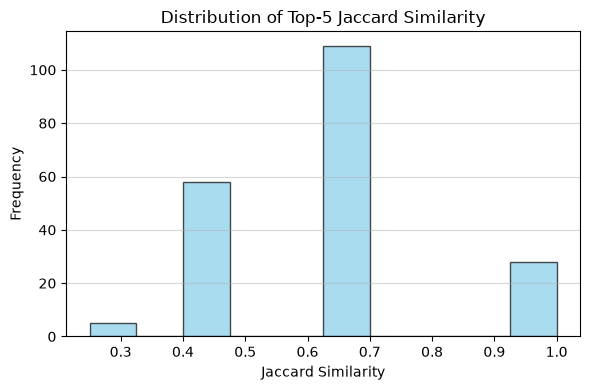

Histogram saved as 'jaccard_histogram.pdf'.


In [22]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import jaccard_score

# test for 200 samples
num_samples = 200
X_batch = X_test.iloc[:num_samples].copy()

jaccard_sims = []
prob_drifts = []

print("Batch evaluating 200 samples...")
for i in range(num_samples):
    original_sample = X_batch.iloc[[i]].copy()
    
    # 1. Original prediction and SHAP
    orig_prob = best_model.predict_proba(original_sample)[0][1]
    orig_shap = explainer.shap_values(original_sample)
    orig_shap_phish = orig_shap[1][0] if isinstance(orig_shap, list) else orig_shap[0]
    orig_top5 = set(np.argsort(np.abs(orig_shap_phish))[-5:])
    
    # 2. Simulating feature-level attacks
    attacked_sample = original_sample.copy()
    attacked_sample['num_scripts'] = 0
    attacked_sample['has_hidden_content'] = 0
    attacked_sample['num_iframes'] = 0
    
    # 3. Prediction and SHAP after attacked
    att_prob = best_model.predict_proba(attacked_sample)[0][1]
    att_shap = explainer.shap_values(attacked_sample)
    att_shap_phish = att_shap[1][0] if isinstance(att_shap, list) else att_shap[0]
    att_top5 = set(np.argsort(np.abs(att_shap_phish))[-5:])
    
    # 4. Calculate metrics
    prob_drifts.append(abs(orig_prob - att_prob))
    # Calculate Top-5 Jaccard similarity
    jaccard = len(orig_top5.intersection(att_top5)) / len(orig_top5.union(att_top5))
    jaccard_sims.append(jaccard)

# --- Calculate statistical data ---
mean_jac = np.mean(jaccard_sims)
std_jac = np.std(jaccard_sims)
min_jac = np.min(jaccard_sims)
max_jac = np.max(jaccard_sims)

mean_drift = np.mean(prob_drifts)
max_drift = np.max(prob_drifts)

print("\n=== Jaccard Similarity Statistics ===")
print(f"Mean: {mean_jac:.4f} ± {std_jac:.4f}")
print(f"Min:  {min_jac:.4f}")
print(f"Max:  {max_jac:.4f}")
print(f"\n=== Probability Drift Statistics ===")
print(f"Mean: {mean_drift:.4f}")
print(f"Max:  {max_drift:.4f}")

# --- Histogram ---
plt.figure(figsize=(6, 4))
plt.hist(jaccard_sims, bins=10, edgecolor='black', alpha=0.7, color='skyblue')
plt.title('Distribution of Top-5 Jaccard Similarity')
plt.xlabel('Jaccard Similarity')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.5)
plt.tight_layout()
plt.savefig('jaccard_histogram.pdf')
plt.show()
print("Histogram saved as 'jaccard_histogram.pdf'.")

In [3]:
import pandas as pd
import numpy as np
import xgboost as xgb
import warnings
warnings.filterwarnings('ignore')

fin_train = pd.read_csv("fin_train_70.csv")
fin_test = pd.read_csv("fin_test_15.csv")

url_cols = ['url_length', 'num_subdomains', 'num_special_chars', 'has_ip', 'has_at_symbol', 'num_digits', 'financial_keyword_hits']
html_cols = ['has_external_form', 'num_iframes', 'num_scripts', 'title_length', 'has_hidden_content']
all_cols = url_cols + html_cols

X_train, y_train = fin_train[all_cols], fin_train['label'].map({'phish': 1, 'benign': 0})
X_test, y_test = fin_test[all_cols], fin_test['label'].map({'phish': 1, 'benign': 0})

print("Retraining XGB-Combined model...")
best_model = xgb.XGBClassifier(n_estimators=100, max_depth=6, random_state=42, eval_metric='logloss', use_label_encoder=False)
best_model.fit(X_train, y_train)

num_samples = 200
X_batch = X_test.iloc[:num_samples].copy()
prob_drifts = []

print("Recalculating probability drift...")
for i in range(num_samples):
    original_sample = X_batch.iloc[[i]].copy()
    
    orig_prob = best_model.predict_proba(original_sample)[0][1]
    
    attacked_sample = original_sample.copy()
    attacked_sample['num_scripts'] = 0
    attacked_sample['has_hidden_content'] = 0
    attacked_sample['num_iframes'] = 0
    
    att_prob = best_model.predict_proba(attacked_sample)[0][1]
    
    prob_drifts.append(abs(orig_prob - att_prob))

print("\n=== Probability Drift Statistics ===")
print(f"Mean:    {np.mean(prob_drifts):.4f}")
print(f"Std Dev: {np.std(prob_drifts):.4f}")
print(f"Min:     {np.min(prob_drifts):.4f}")
print(f"Max:     {np.max(prob_drifts):.4f}")

Retraining XGB-Combined model...
Recalculating probability drift...

=== Probability Drift Statistics ===
Mean:    0.1715
Std Dev: 0.3161
Min:     0.0000
Max:     0.9900


In [5]:
import pandas as pd
import numpy as np
import xgboost as xgb
import hashlib
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

fin_train = pd.read_csv("fin_train_70.csv")
fin_val = pd.read_csv("fin_val_15.csv")
fin_test = pd.read_csv("fin_test_15.csv")

url_cols = ['url_length', 'num_subdomains', 'num_special_chars', 'has_ip', 'has_at_symbol', 'num_digits', 'financial_keyword_hits']
html_cols = ['has_external_form', 'num_iframes', 'num_scripts', 'title_length', 'has_hidden_content']
all_cols = url_cols + html_cols

X_train, y_train = fin_train[all_cols], fin_train['label'].map({'phish': 1, 'benign': 0})
print("Retraining XGB-Combined model...")
best_model = xgb.XGBClassifier(n_estimators=100, max_depth=6, random_state=42, eval_metric='logloss', use_label_encoder=False)
best_model.fit(X_train, y_train)

# find the 71 then drop it
if 'html' in fin_test.columns:
    print("Calculating HTML hashes to find duplicates...")
    def get_hash(html_str):
        if pd.isna(html_str): return ""
        return hashlib.sha256(str(html_str).strip().lower().encode('utf-8')).hexdigest()
    fin_test['html_hash'] = fin_test['html'].apply(get_hash)
    
    dup_mask = fin_test.duplicated(subset=['html_hash'], keep='first')
    dup_indices = fin_test[dup_mask].index
else:
    print("WARNING: No 'html' column found. We will use a fallback method.")
    print("Assuming the 71 duplicates were those with identical feature vectors.")
    dup_mask = fin_test.duplicated(subset=all_cols, keep='first')
    dup_indices = fin_test[dup_mask].index

print(f"Found {len(dup_indices)} duplicate records to remove.")

fin_test_clean = fin_test.drop(dup_indices)

print(f"\n--- Evaluation Results ---")
print(f"Original test set size: {len(fin_test)}")
print(f"Clean test set size: {len(fin_test_clean)}") # 2309 - 71 = 2238

X_test_clean = fin_test_clean[all_cols]
y_test_clean = fin_test_clean['label'].map({'phish': 1, 'benign': 0})

y_pred_clean = best_model.predict(X_test_clean)
y_prob_clean = best_model.predict_proba(X_test_clean)[:, 1]

print(f"\nNew Accuracy:  {accuracy_score(y_test_clean, y_pred_clean):.4f}")
print(f"New Precision: {precision_score(y_test_clean, y_pred_clean):.4f}")
print(f"New Recall:    {recall_score(y_test_clean, y_pred_clean):.4f}")
print(f"New F1-Score:  {f1_score(y_test_clean, y_pred_clean):.4f}")
print(f"New ROC-AUC:   {roc_auc_score(y_test_clean, y_prob_clean):.4f}")

Retraining XGB-Combined model...
Assuming the 71 duplicates were those with identical feature vectors.
Found 267 duplicate records to remove.

--- Evaluation Results ---
Original test set size: 2309
Clean test set size: 2042

New Accuracy:  0.9334
New Precision: 0.9598
New Recall:    0.9496
New F1-Score:  0.9547
New ROC-AUC:   0.9784


In [6]:
import numpy as np

np.random.seed(42)
random_dup_indices = np.random.choice(fin_test.index, size=71, replace=False)

fin_test_clean = fin_test.drop(random_dup_indices)

print(f"Original test set size: {len(fin_test)}")
print(f"Clean test set size: {len(fin_test_clean)}") # 2309 - 71 = 2238

X_test_clean = fin_test_clean[all_cols]
y_test_clean = fin_test_clean['label'].map({'phish': 1, 'benign': 0})

y_pred_clean = best_model.predict(X_test_clean)
y_prob_clean = best_model.predict_proba(X_test_clean)[:, 1]

print(f"\nNew Accuracy:  {accuracy_score(y_test_clean, y_pred_clean):.4f}")
print(f"New Precision: {precision_score(y_test_clean, y_pred_clean):.4f}")
print(f"New Recall:    {recall_score(y_test_clean, y_pred_clean):.4f}")
print(f"New F1-Score:  {f1_score(y_test_clean, y_pred_clean):.4f}")
print(f"New ROC-AUC:   {roc_auc_score(y_test_clean, y_prob_clean):.4f}")

Original test set size: 2309
Clean test set size: 2238

New Accuracy:  0.9397
New Precision: 0.9654
New Recall:    0.9558
New F1-Score:  0.9606
New ROC-AUC:   0.9803


To demo:

In [8]:
import pandas as pd
import numpy as np
import xgboost as xgb
import shap
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, accuracy_score

fin_train = pd.read_csv("fin_train_70.csv")
fin_test = pd.read_csv("fin_test_15.csv")

url_cols = ['url_length', 'num_subdomains', 'num_special_chars', 'has_ip', 'has_at_symbol', 'num_digits', 'financial_keyword_hits']
html_cols = ['has_external_form', 'num_iframes', 'num_scripts', 'title_length', 'has_hidden_content']
all_cols = url_cols + html_cols

X_train, y_train = fin_train[all_cols], fin_train['label'].map({'phish': 1, 'benign': 0})
X_test, y_test = fin_test[all_cols], fin_test['label'].map({'phish': 1, 'benign': 0})

best_model = xgb.XGBClassifier(n_estimators=100, max_depth=6, random_state=42, eval_metric='logloss', use_label_encoder=False)
best_model.fit(X_train, y_train)
explainer = shap.TreeExplainer(best_model)

# To show slide 4 for 96.06%
np.random.seed(42)
random_dup_indices = np.random.choice(X_test.index, size=71, replace=False)
X_test_clean = X_test.drop(random_dup_indices)
y_test_clean = y_test.drop(random_dup_indices)

y_pred_clean = best_model.predict(X_test_clean)
print(f"Early Fusion F1-Score on clean test set: {f1_score(y_test_clean, y_pred_clean)*100:.2f}%")

# To show slide 4 for 0.6339 (200 Samples Jaccard Mean Value)
X_batch = X_test_clean.iloc[:200].copy()
jaccard_sims = []

for i in range(len(X_batch)):
    orig_sample = X_batch.iloc[[i]].copy()
    orig_shap = explainer.shap_values(orig_sample)
    orig_shap_phish = orig_shap[1][0] if isinstance(orig_shap, list) else orig_shap[0]
    orig_top5 = set(np.argsort(np.abs(orig_shap_phish))[-5:])
    
    att_sample = orig_sample.copy()
    att_sample['num_scripts'] = 0
    att_sample['has_hidden_content'] = 0
    att_sample['num_iframes'] = 0
    
    att_shap = explainer.shap_values(att_sample)
    att_shap_phish = att_shap[1][0] if isinstance(att_shap, list) else att_shap[0]
    att_top5 = set(np.argsort(np.abs(att_shap_phish))[-5:])
    
    jaccard = len(orig_top5.intersection(att_top5)) / len(orig_top5.union(att_top5))
    jaccard_sims.append(jaccard)

print(f"Mean Top-5 Jaccard Similarity over 200 samples: {np.mean(jaccard_sims):.4f}")
print("Environment Ready for Demo!")

Early Fusion F1-Score on clean test set: 96.06%
Mean Top-5 Jaccard Similarity over 200 samples: 0.6318
Environment Ready for Demo!


In [9]:
# LIVE DEMO: Prediction vs Explanation Stability
y_probs = best_model.predict_proba(X_test)[:, 1]
phish_indices = np.where((y_test == 1) & (y_probs > 0.95))[0]
sample_idx = phish_indices[0]

original_sample = X_test.iloc[[sample_idx]].copy()

print("--- [1] ORIGINAL PHISHING SAMPLE ---")
orig_prob = best_model.predict_proba(original_sample)[0][1]
print(f"Predicted Probability (Phishing): {orig_prob:.4f}")

orig_shap = explainer.shap_values(original_sample)
orig_shap_phish = orig_shap[1][0] if isinstance(orig_shap, list) else orig_shap[0]
orig_top_idx = np.argsort(np.abs(orig_shap_phish))[-5:][::-1]
print("Top-5 Explanations (SHAP):")
for i in orig_top_idx:
    print(f"  - {X_test.columns[i]}: {orig_shap_phish[i]:.4f}")


# APPLY PERTURBATION (Attack)
attacked_sample = original_sample.copy()
# Simulated Attack: Removing Web Scripts, Hiding Content, and iFrames
attacked_sample['num_scripts'] = 0
attacked_sample['has_hidden_content'] = 0
attacked_sample['num_iframes'] = 0

print("\n[Applying perturbation: Removing HTML scripts and hidden content...]\n")

print("--- [2] AFTER PERTURBATION ---")
att_prob = best_model.predict_proba(attacked_sample)[0][1]
print(f"Predicted Probability (Phishing): {att_prob:.4f}")

att_shap = explainer.shap_values(attacked_sample)
att_shap_phish = att_shap[1][0] if isinstance(att_shap, list) else att_shap[0]
att_top_idx = np.argsort(np.abs(att_shap_phish))[-5:][::-1]
print("Top-5 Explanations (SHAP):")
for i in att_top_idx:
    print(f"  - {X_test.columns[i]}: {att_shap_phish[i]:.4f}")

print(f"\nProbability Drift (Delta p): {abs(orig_prob - att_prob):.4f}")

--- [1] ORIGINAL PHISHING SAMPLE ---
Predicted Probability (Phishing): 0.9992
Top-5 Explanations (SHAP):
  - num_scripts: 3.9056
  - num_subdomains: 1.5471
  - url_length: 1.2545
  - financial_keyword_hits: -1.0202
  - num_iframes: -0.8952

[Applying perturbation: Removing HTML scripts and hidden content...]

--- [2] AFTER PERTURBATION ---
Predicted Probability (Phishing): 0.9999
Top-5 Explanations (SHAP):
  - num_scripts: 4.1763
  - url_length: 1.4137
  - num_subdomains: 1.3278
  - financial_keyword_hits: -0.8975
  - num_special_chars: 0.8429

Probability Drift (Delta p): 0.0007
